# Results - FST Dataset

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# --- Paths ---
FILEPATH_RAW       = "oa_us_pipeline_data/2025-08-19_15-42-46_EXP/data/.extraction/intensity_extraction_RAW_DATA_MUSCLE.xlsx"
FILEPATH_CORRECTED = "oa_us_pipeline_data/2025-08-19_15-42-46_EXP/data/.extraction/intensity_extraction_FC_MUSCLE.xlsx"
FILEPATH_SKIN      = "oa_us_pipeline_data/2025-08-19_15-42-46_EXP/data/.extraction/intensity_extraction_RAW_DATA_SKIN.xlsx"
METADATA_FILE      = "meta/MSOT_3_Metadata/MSOT_3_FST_Lookup_MS.xlsx"

# --- Constants ---
GROUP_LABELS = ["Type I", "Type II", "Type III", "Type IV", "Type V"]
PALETTE      = ["#E9CEB3", "#D9B593", "#C29F80", "#A37655", "#915F37"]
Y_RANGE      = (-0.2, 1.2)

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

DF_META = pd.read_excel(METADATA_FILE, sheet_name="FST")[["Study ID", "FST Scalebar"]]


def prepare_df(filepath, wav, group_labels=GROUP_LABELS):
    df = pd.read_excel(filepath, sheet_name=wav)[["subject_id", "original_firstorder_Mean"]]
    df = df[df["subject_id"].str.split("-").str[0].str.isnumeric()]
    df["Study ID"] = df["subject_id"].str.split("-").str[1].astype(int)
    df = df.merge(DF_META, on="Study ID", how="left")
    df.rename(columns={"original_firstorder_Mean": "Mean Intensity"}, inplace=True)
    df = df[df["FST Scalebar"] != 6]
    df = df.sort_values(by="FST Scalebar")
    df["FST Scalebar LABEL"] = df["FST Scalebar"].apply(
        lambda x: group_labels[x - 1] if x <= len(group_labels) else "Unknown"
    )
    df = df[~df["subject_id"].str.contains("003-009-048-000")]
    df["Mean Intensity"] = (df["Mean Intensity"] - df["Mean Intensity"].min()) / (
        df["Mean Intensity"].max() - df["Mean Intensity"].min()
    )
    return df


def compute_spearman(df):
    rho, p = spearmanr(df["FST Scalebar"], df["Mean Intensity"])
    return f"ρ = {rho:.2f}, p < 0.001" if p < 0.001 else f"ρ = {rho:.2f}, p = {p:.4f}"


def plot_fst(wav, x_col="FST Scalebar LABEL", showfliers=False):
    datasets = [prepare_df(fp, wav) for fp in [FILEPATH_SKIN, FILEPATH_RAW, FILEPATH_CORRECTED]]
    titles   = [
        f"Skin Signal ({wav}nm)",
        f"Muscle Signal (Raw, {wav}nm)",
        f"Muscle Signal (Corrected, {wav}nm)",
    ]
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, title, df in zip(axes, titles, datasets):
        sns.boxplot(x=x_col, y="Mean Intensity", hue="FST Scalebar",
                    data=df, palette=PALETTE, ax=ax, legend=False, showfliers=showfliers)
        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("FST")
        ax.set_ylabel("PA Intensity (a.u.)")
        ax.set_ylim(Y_RANGE)
        ax.text(0.5, 0.95, compute_spearman(df), transform=ax.transAxes,
                ha="center", va="top", fontsize=10,
                bbox=dict(facecolor="white", edgecolor="gray", boxstyle="round,pad=0.2"))
    plt.tight_layout()
    os.makedirs("figures", exist_ok=True)
    plt.savefig(f"figures/fst_results_{wav}nm.pdf", bbox_inches="tight", dpi=300)
    plt.show()


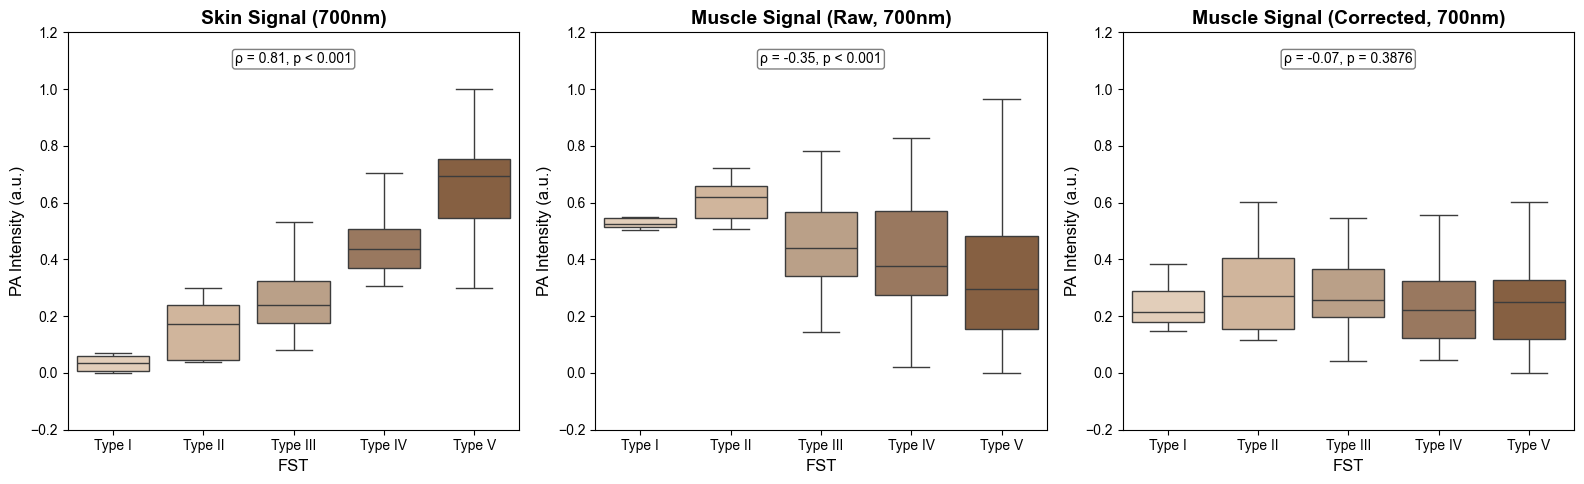

In [15]:
plot_fst('700')
# plot_fst('850')
# plot_fst('980')
